In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
file_path = "Crop_recommendation.csv"

crop = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", crop.shape)

crop.head()

Dataset loaded successfully!
Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
print("Columns:")
print(crop.columns.tolist())

print("\nMissing Values:")
print(crop.isnull().sum())

print("\nDuplicate Rows:")
print(crop.duplicated().sum())

print("\nTotal Crops:")
print(crop["label"].nunique())

print("\nCrop Names:")
print(sorted(crop["label"].unique()))

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate Rows:
0

Total Crops:
22

Crop Names:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


In [ ]:
crop["label"].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

In [ ]:
feature_columns = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

X = crop[feature_columns]

y = crop["label"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (2200, 7)
y Shape: (2200,)


: Dataset ko 2 parts me divide kar rahe hain.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1760, 7)
Testing Data: (440, 7)


hum ek model nahi, multiple models use kar rahe hain.

Total 8 models hain:

In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

print("4 Models Ready:")
for name in models:
    print("-", name)

4 Models Ready:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM


In [ ]:
results = []

trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    trained_models[name] = model

print("All models trained successfully!")

All models trained successfully!


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df["Accuracy (%)"] = (
    results_df["Accuracy"] * 100
).round(2)

results_df[["Model", "Accuracy (%)"]]

,Model,Accuracy (%)
0,Random Forest,99.32
1,SVM,98.41
2,Decision Tree,97.95
3,Logistic Regression,97.27


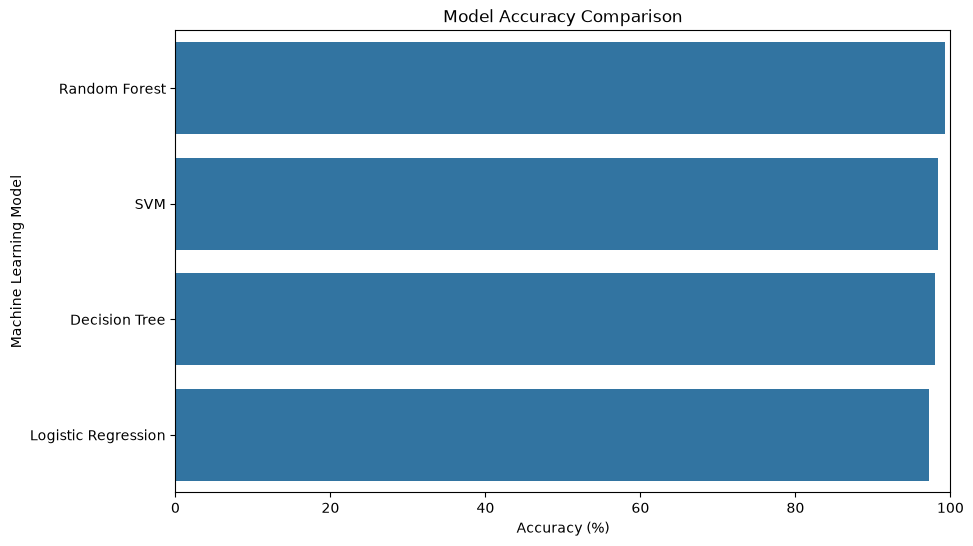

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Accuracy (%)",
    y="Model"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.ylabel("Machine Learning Model")

plt.xlim(0, 100)

plt.show()

In [ ]:
best_model_name = results_df.loc[0, "Model"]

best_model = trained_models[best_model_name]

best_accuracy = results_df.loc[0, "Accuracy (%)"]

print("Best Model:", best_model_name)
print("Accuracy:", best_accuracy, "%")

Best Model: Random Forest
Accuracy: 99.32 %


In [ ]:
best_predictions = best_model.predict(X_test)

print("Classification Report")
print()

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Classification Report

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
    

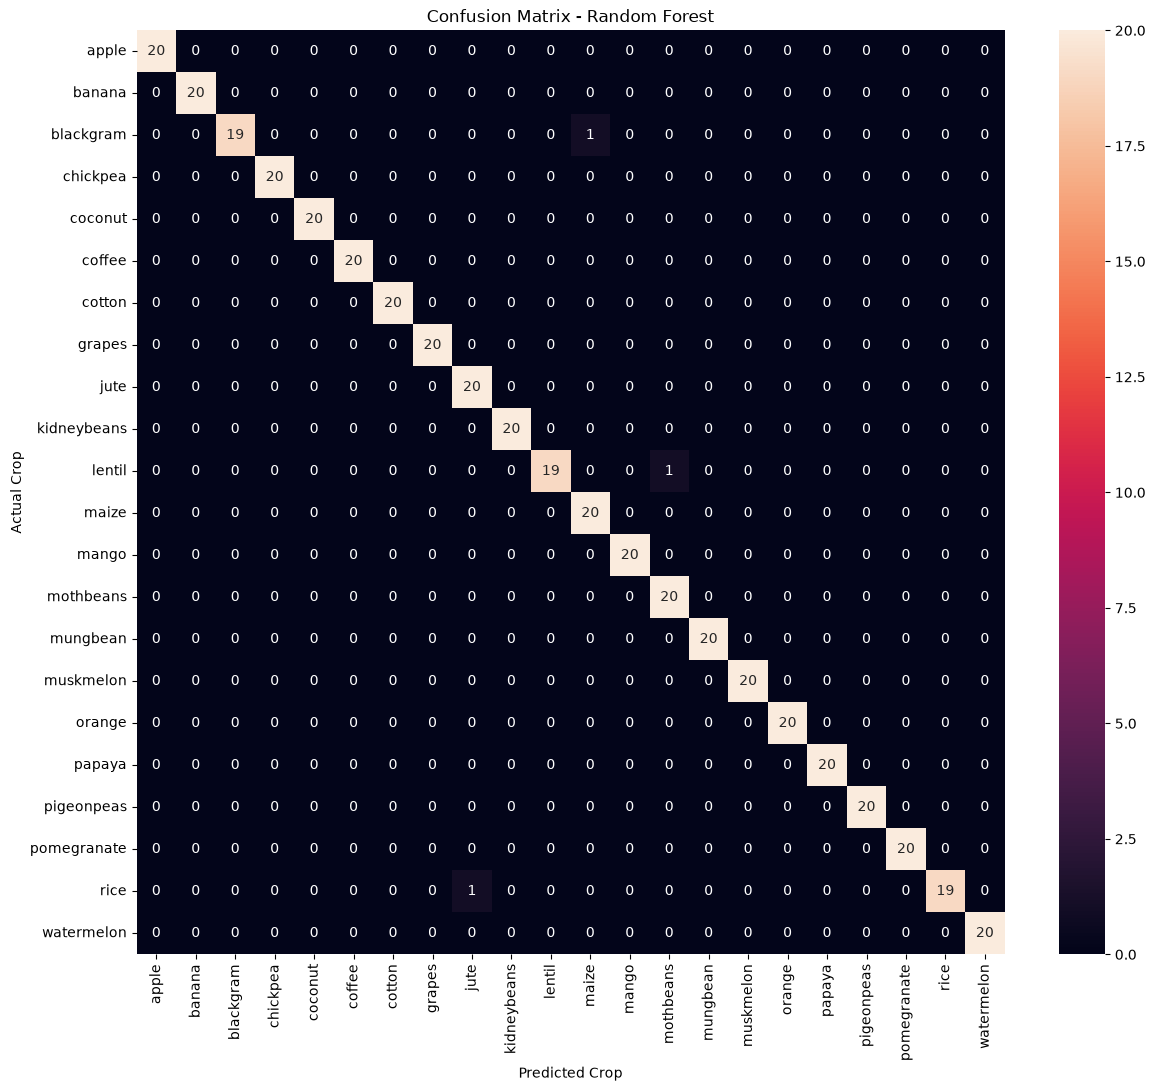

In [ ]:
crop_names = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=crop_names
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=crop_names,
    yticklabels=crop_names
)

plt.title("Confusion Matrix - " + best_model_name)

plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.show()

Suppose user inputs:

N = 90
P = 42
K = 43

Temperature = 20
Humidity = 82
pH = 6.5
Rainfall = 202

Model sirf ek crop nahi dega.

Ye Top 3 crops dega:

Crop           Probability

rice           97%
jute            2%
papaya          1%

In [ ]:
def recommend_top_3(
    N,
    P,
    K,
    temperature,
    humidity,
    ph,
    rainfall,
    model=best_model
):

    input_data = pd.DataFrame(
        [[
            N,
            P,
            K,
            temperature,
            humidity,
            ph,
            rainfall
        ]],
        columns=feature_columns
    )

    probabilities = model.predict_proba(input_data)[0]

    classes = model.classes_

    top_indices = np.argsort(probabilities)[::-1][:3]

    recommendations = pd.DataFrame({

        "Crop": classes[top_indices],

        "Probability (%)":
        (probabilities[top_indices] * 100).round(2)

    })

    return recommendations.reset_index(drop=True)

In [ ]:
N = 90
P = 42
K = 43

temperature = 20.88
humidity = 82.00

ph = 6.50

rainfall = 202.94


print("Input Data")

print("N =", N)
print("P =", P)
print("K =", K)

print("Temperature =", temperature)
print("Humidity =", humidity)

print("pH =", ph)

print("Rainfall =", rainfall)


print("\nTop 3 Recommended Crops:")

recommend_top_3(
    N,
    P,
    K,
    temperature,
    humidity,
    ph,
    rainfall
)

Input Data
N = 90
P = 42
K = 43
Temperature = 20.88
Humidity = 82.0
pH = 6.5
Rainfall = 202.94

Top 3 Recommended Crops:


,Crop,Probability (%)
0,rice,95.0
1,jute,5.0
2,pomegranate,0.0


Run karne par first dataset record show hoga.

In [ ]:
test_row = crop.iloc[0]

test_row

N                      90
P                      42
K                      43
temperature     20.879744
humidity        82.002744
ph               6.502985
rainfall       202.935536
label                rice
Name: 0, dtype: object

In [ ]:
print("Actual Crop:")

print(test_row["label"])

Actual Crop:
rice


In [ ]:
recommend_top_3(

    test_row["N"],

    test_row["P"],

    test_row["K"],

    test_row["temperature"],

    test_row["humidity"],

    test_row["ph"],

    test_row["rainfall"]

)

,Crop,Probability (%)
0,rice,95.0
1,jute,5.0
2,pomegranate,0.0


In [ ]:
print("Enter Soil and Weather Details")
print("--------------------------------")


N = get_float(
    "Enter Nitrogen (N): "
)

P = get_float(
    "Enter Phosphorus (P): "
)

K = get_float(
    "Enter Potassium (K): "
)

temperature = get_float(
    "Enter Temperature (°C): "
)

humidity = get_float(
    "Enter Humidity (%): "
)

ph = get_float(
    "Enter Soil pH: "
)

rainfall = get_float(
    "Enter Rainfall (mm): "
)


print("\nTop 3 Recommended Crops:")


recommend_top_3(

    N,

    P,

    K,

    temperature,

    humidity,

    ph,

    rainfall

)

Enter Soil and Weather Details
--------------------------------


Enter Nitrogen (N):  95
Enter Phosphorus (P):  42
Enter Potassium (K):  26
Enter Temperature (°C):  28
Enter Humidity (%):  42
Enter Soil pH:  9
Enter Rainfall (mm):  23



Top 3 Recommended Crops:


,Crop,Probability (%)
0,muskmelon,42.67
1,maize,18.00
2,coffee,13.33


All Models Prediction Compare

In [ ]:
Dataset
   ↓
Data Checking
   ↓
Features / Target
   ↓
Train-Test Split
   ↓
Multiple ML Models
   ↓
Train Models
   ↓
Accuracy Comparison
   ↓
Best Model Selection
   ↓
Evaluation
   ↓
User Input
   ↓
Top 3 Crop Recommendation